In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
turbinesJanuary = pd.read_parquet("/Users/zsquirrel/Downloads/Alta10_Turbine_Points_10m_2026-01.parquet")
turbinesFebruary = pd.read_parquet("/Users/zsquirrel/Downloads/Alta10_Turbine_Points_10m_2026-02.parquet")
turbinesMarch = pd.read_parquet("/Users/zsquirrel/Downloads/Alta10_Turbine_Points_10m_2026-03.parquet")
turbinesApril = pd.read_parquet("/Users/zsquirrel/Downloads/Alta10_Turbine_Points_10m_2026-04.parquet")
turbinesMay = pd.read_parquet("/Users/zsquirrel/Downloads/Alta10_Turbine_Points_10m_2026-05.parquet")
turbinesJune = pd.read_parquet("/Users/zsquirrel/Downloads/Alta10_Turbine_Points_10m_2026-06.parquet")
turbinesJuly = pd.read_parquet("/Users/zsquirrel/Downloads/Alta10_Turbine_Points_10m_2026-07.parquet")
turbinesAugust = pd.read_parquet("/Users/zsquirrel/Downloads/Alta10_Turbine_Points_10m_2026-08.parquet")
turbinesSeptember = pd.read_parquet("/Users/zsquirrel/Downloads/Alta10_Turbine_Points_10m_2026-09.parquet")

# Combine January through September into one DataFrame
turbines_raw = pd.concat([
    turbinesJanuary,
    turbinesFebruary,
    turbinesMarch,
    turbinesApril,
    turbinesMay,
    turbinesJune,
    turbinesJuly,
    turbinesAugust,
    turbinesSeptember
], axis=0)

print("Combined shape:", turbines_raw.shape)
print("Column names:", turbines_raw.columns[:10].tolist())
print("Index names:", turbines_raw.index.names)

display(turbines_raw.head())

Combined shape: (39018, 799)
Column names: ['utcTime', 'ALTA10-SCEWF-WTG150-AirDensity', 'ALTA10-SCEWF-WTG150-KPI-TemperatureAmbient-Merged', 'ALTA10-SCEWF-WTG150-KPI-RealPowerAC', 'ALTA10-SCEWF-WTG150-KPI-TheoreticalPower', 'ALTA10-SCEWF-WTG150-KPI-WindSpeed', 'ALTA10-SCEWF-WTG150-KPI-TemperatureAmbient', 'ALTA10-SCEWF-WTG150-RealPowerAC', 'ALTA10-SCEWF-WTG150-NacellePosition', 'ALTA10-SCEWF-WTG150-BladePosition2']
Index names: ['DataTimeStamp']


,utcTime,ALTA10-SCEWF-WTG150-AirDensity,ALTA10-SCEWF-WTG150-KPI-TemperatureAmbient-Merged,ALTA10-SCEWF-WTG150-KPI-RealPowerAC,ALTA10-SCEWF-WTG150-KPI-TheoreticalPower,ALTA10-SCEWF-WTG150-KPI-WindSpeed,ALTA10-SCEWF-WTG150-KPI-TemperatureAmbient,ALTA10-SCEWF-WTG150-RealPowerAC,ALTA10-SCEWF-WTG150-NacellePosition,ALTA10-SCEWF-WTG150-BladePosition2,...,ALTA10-SCEWF-WTG197-NacellePosition,ALTA10-SCEWF-WTG197-BladePosition1,ALTA10-SCEWF-WTG197-BladePosition2,ALTA10-SCEWF-WTG197-BladePosition3,ALTA10-SCEWF-WTG197-BladeSetpointPosition1,ALTA10-SCEWF-WTG197-BladeSetpointPosition2,ALTA10-SCEWF-WTG197-BladeSetpointPosition3,ALTA10-SCEWF-WTG197-WindSpeed,ALTA10-SCEWF-WTG197-WindDirection,ALTA10-SCEWF-WTG197-WindDirectionRelative
DataTimeStamp,,,,,,,,,,,,,,,,,,,,,
2026-01-01 00:00:00,2026-01-01 08:00:00,1.092081,8.299405,672.60510,746.68463,6.906036,8.299405,670.286714,118.785714,-1.056245,...,62.500000,-0.15625,0.35788,-0.211483,-0.164664,0.369037,-0.207469,8.664497,54.739130,-6.454545
2026-01-01 00:10:00,2026-01-01 08:10:00,0.800856,8.573889,541.30096,466.00030,6.609679,8.573889,542.747853,117.066667,-1.077751,...,59.000000,NaN,NaN,NaN,NaN,NaN,NaN,8.000924,52.763514,-5.510949
2026-01-01 00:20:00,2026-01-01 08:20:00,1.089478,8.972823,237.94884,292.86000,5.210308,8.972823,239.185173,118.812500,-0.445800,...,58.666667,NaN,NaN,NaN,NaN,NaN,NaN,8.207936,53.654930,-4.808824
2026-01-01 00:30:00,2026-01-01 08:30:00,0.800936,8.531316,503.22354,443.03992,6.510418,8.531316,504.556470,NaN,-1.205972,...,67.333333,NaN,NaN,NaN,NaN,NaN,NaN,8.099642,60.771812,-6.313869
2026-01-01 00:40:00,2026-01-01 08:40:00,1.090836,8.621079,444.42767,500.71185,6.093416,8.621079,444.157211,130.000000,-1.205672,...,67.100000,NaN,NaN,NaN,NaN,NaN,NaN,8.257563,60.806897,-6.318519


In [4]:
import pandas as pd
import re

# Create formatted dataframe
turbines = turbines_raw.copy()

# Set UTC timestamp as index
turbines["utcTime"] = pd.to_datetime(turbines["utcTime"])
turbines = turbines.set_index("utcTime")
turbines.index.name = "utc_time"

# Extract turbine ID and variable names
parsed = []

for col in turbines.columns:
    match = re.fullmatch(r"ALTA10-SCEWF-(WTG\d+)-(.+)", col)

    if match is None:
        raise ValueError(f"Unexpected column name: {col}")

    turbine = match.group(1).lower()
    original = match.group(2)
    is_kpi = original.startswith("KPI-")

    name = original.removeprefix("KPI-").replace("-", "_")
    variable = re.sub(r"(?<!^)(?=[A-Z0-9])", "_", name).lower()
    variable = re.sub(r"_+", "_", variable)

    parsed.append((turbine, variable, is_kpi))

# Match the original January naming convention:
# KPI fields keep the base name; raw duplicates get "_2"
kpi_names = {
    (turbine, variable)
    for turbine, variable, is_kpi in parsed
    if is_kpi
}

new_columns = []

for turbine, variable, is_kpi in parsed:
    if not is_kpi and (turbine, variable) in kpi_names:
        variable += "_2"

    new_columns.append((turbine, variable))

# Create MultiIndex columns
turbines.columns = pd.MultiIndex.from_tuples(
    new_columns,
    names=["turbine", "variable"]
)

# Sort rows and columns
turbines = turbines.sort_index().sort_index(axis=1)

# Verify
print("Shape:", turbines.shape)
print("Start:", turbines.index.min())
print("End:", turbines.index.max())
print("Turbines:", turbines.columns.get_level_values("turbine").nunique())
print("Duplicate timestamps:", turbines.index.duplicated().sum())
print("Duplicate columns:", turbines.columns.duplicated().sum())

display(turbines.head())

Shape: (39018, 798)
Start: 2026-01-01 08:00:00
End: 2026-09-29 06:50:00
Turbines: 47
Duplicate timestamps: 0
Duplicate columns: 0


turbine                  wtg150                                    \
variable            air_density blade_position_2 blade_position_3   
utc_time                                                            
2026-01-01 08:00:00    1.092081        -1.056245        -0.643520   
2026-01-01 08:10:00    0.800856        -1.077751        -0.680390   
2026-01-01 08:20:00    1.089478        -0.445800        -0.039797   
2026-01-01 08:30:00    0.800936        -1.205972        -0.786801   
2026-01-01 08:40:00    1.090836        -1.205672        -0.786363   

turbine                                                                  \
variable            blade_setpoint_position_1 blade_setpoint_position_2   
utc_time                                                                  
2026-01-01 08:00:00                  2.307242                 -0.892182   
2026-01-01 08:10:00                  2.354385                 -0.845038   
2026-01-01 08:20:00                  2.813232                 -0.386191   
2026-01-01 08:30:00                       NaN                       NaN   
2026-01-01 08:40:00                       NaN                       NaN   

turbine                                                                        \
variable            blade_setpoint_position_3 nacelle_position real_power_a_c   
utc_time                                                                        
2026-01-01 08:00:00                 -0.471435       118.785714      672.60510   
2026-01-01 08:10:00                 -0.424893       117.066667      541.30096   
2026-01-01 08:20:00                  0.032674       118.812500      237.94884   
2026-01-01 08:30:00                       NaN              NaN      503.22354   
2026-01-01 08:40:00                       NaN       130.000000      444.42767   

turbine                                                   ...  \
variable            real_power_a_c_2 temperature_ambient  ...   
utc_time                                                  ...   
2026-01-01 08:00:00       670.286714            8.299405  ...   
2026-01-01 08:10:00       542.747853            8.573889  ...   
2026-01-01 08:20:00       239.185173            8.972823  ...   
2026-01-01 08:30:00       504.556470            8.531316  ...   
2026-01-01 08:40:00       444.157211            8.621079  ...   

turbine                       wtg197                                  \
variable            nacelle_position real_power_a_c real_power_a_c_2   
utc_time                                                               
2026-01-01 08:00:00        62.500000      1232.1998      1229.936331   
2026-01-01 08:10:00        59.000000       990.2687       990.641605   
2026-01-01 08:20:00        58.666667      1074.2076      1074.568828   
2026-01-01 08:30:00        67.333333      1108.8040      1108.957917   
2026-01-01 08:40:00        67.100000      1124.4481      1123.277779   

turbine                                                             \
variable            temperature_ambient temperature_ambient_merged   
utc_time                                                             
2026-01-01 08:00:00            6.258348                   6.258348   
2026-01-01 08:10:00            6.331188                   6.331188   
2026-01-01 08:20:00            6.456590                   6.456590   
2026-01-01 08:30:00            6.545990                   6.545990   
2026-01-01 08:40:00            6.563307                   6.563307   

turbine                                                                       \
variable            theoretical_power wind_direction wind_direction_relative   
utc_time                                                                       
2026-01-01 08:00:00         1418.4381      54.739130               -6.454545   
2026-01-01 08:10:00          817.2081      52.763514               -5.510949   
2026-01-01 08:20:00         1234.4576      53.654930               -4.808824   
2026-01-01 08:30:00          843.8777      60.771812      

In [6]:
import seaborn as sns

# Extract raw wind speeds from every turbine
wind = turbines.xs("wind_speed", axis=1, level="variable").copy()

# Standardize turbine names
wind.columns = wind.columns.str.lower()

# Convert values to numeric
wind = wind.apply(pd.to_numeric, errors="coerce")

# Exclude turbines with documented generator failures
wind = wind.drop(columns=["wtg169", "wtg183"], errors="ignore")

# Flag clearly suspicious readings (preliminary threshold)
wind = wind.where((wind >= 0) & (wind <= 40))

print("Dataset shape:", wind.shape)
print(wind.head())

Dataset shape: (39018, 45)
turbine                wtg150    wtg151    wtg152    wtg153    wtg154  \
utc_time                                                                
2026-01-01 08:00:00  6.906036  5.730449  5.862610  5.969328  4.760764   
2026-01-01 08:10:00  6.609679  5.477940  5.610396  5.871838  4.329586   
2026-01-01 08:20:00  5.210308  4.240477  5.174487  5.721522  4.978105   
2026-01-01 08:30:00  6.510418  5.377338  5.057247  5.432190  4.729747   
2026-01-01 08:40:00  6.093416  5.174675  5.664870  6.017239  4.808846   

turbine                wtg155    wtg156    wtg157    wtg158    wtg159  ...  \
utc_time                                                               ...   
2026-01-01 08:00:00  5.551334  5.196425  5.521146  5.178299  4.061986  ...   
2026-01-01 08:10:00  5.762332  4.829579  5.781654  4.966896  5.086618  ...   
2026-01-01 08:20:00  6.281947  5.976226  6.209143  5.305197  5.494353  ...   
2026-01-01 08:30:00  5.460868  4.748529  5.125973  4.821038  5.256970  

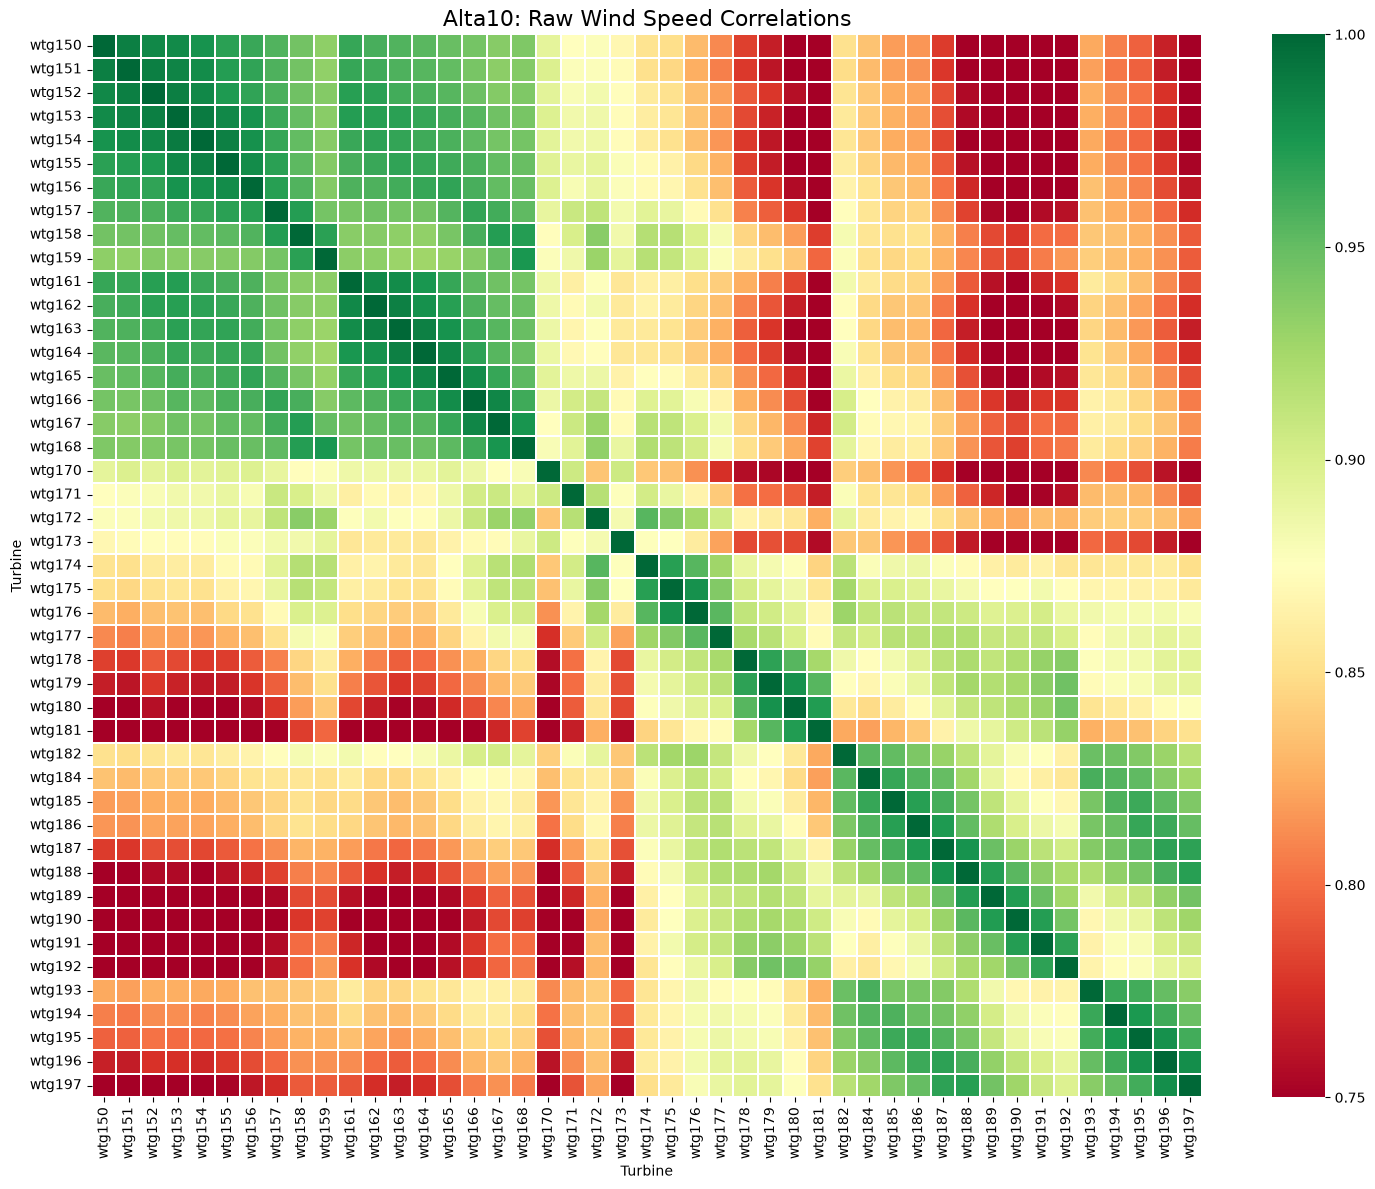

In [7]:
# Correlation between all turbines for similar wind speed patterns
corr_matrix = wind.corr(min_periods=1000)

# Display correlation heatmap
plt.figure(figsize=(15, 12))

sns.heatmap(
    corr_matrix,
    cmap="RdYlGn",       # Red → Yellow → Green
    vmin=0.75,
    vmax=1.0,
    center=0.875,
    linewidths=0.15
)

plt.title("Alta10: Raw Wind Speed Correlations", fontsize=16)
plt.xlabel("Turbine")
plt.ylabel("Turbine")
plt.tight_layout()
plt.show()

In [8]:
target = "wtg150"

top_partners = (
    corr_matrix[target]
    .drop(target)
    .sort_values(ascending=False)
    .head(5)
)

print(top_partners)

turbine
wtg151    0.987384
wtg152    0.982936
wtg153    0.981579
wtg154    0.977078
wtg155    0.969059
Name: wtg150, dtype: float64


In [9]:
results = []

for turbine in corr_matrix.columns:
    top_3 = (
        corr_matrix[turbine]
        .drop(turbine)
        .dropna()
        .nlargest(3)
    )

    results.append({
        "Turbine": turbine,
        "Partner 1": top_3.index[0],
        "Correlation 1": round(top_3.iloc[0], 4),
        "Partner 2": top_3.index[1],
        "Correlation 2": round(top_3.iloc[1], 4),
        "Partner 3": top_3.index[2],
        "Correlation 3": round(top_3.iloc[2], 4)
    })

partners_df = pd.DataFrame(results)

display(partners_df)

,Turbine,Partner 1,Correlation 1,Partner 2,Correlation 2,Partner 3,Correlation 3
0,wtg150,wtg151,0.9874,wtg152,0.9829,wtg153,0.9816
1,wtg151,wtg152,0.9876,wtg150,0.9874,wtg153,0.9849
2,wtg152,wtg153,0.9879,wtg151,0.9876,wtg154,0.9833
3,wtg153,wtg154,0.9897,wtg152,0.9879,wtg151,0.9849
4,wtg154,wtg153,0.9897,wtg155,0.9865,wtg152,0.9833
5,wtg155,wtg154,0.9865,wtg153,0.9829,wtg156,0.9809
6,wtg156,wtg155,0.9809,wtg154,0.9779,wtg153,0.9768
7,wtg157,wtg158,0.9714,wtg156,0.9705,wtg155,0.9692
8,wtg158,wtg167,0.9715,wtg157,0.9714,wtg168,0.9711
9,wtg159,wtg168,0.9747,wtg158,0.9689,wtg167,0.9502


In [10]:
# Evaluate consistency of each turbine's strongest partner
pairs = {
    tuple(sorted([row["Turbine"], row["Partner 1"]]))
    for _, row in partners_df.iterrows()
}

results = []

for a, b in sorted(pairs):
    paired = wind[[a, b]].dropna()
    difference = paired[a] - paired[b]

    results.append({
        "Turbine A": a,
        "Turbine B": b,
        "Correlation": corr_matrix.loc[a, b],
        "Mean Difference": difference.mean(),
        "SD Difference": difference.std(),
        "Observations": len(paired)
    })

difference_df = pd.DataFrame(results)

difference_df = difference_df.sort_values("SD Difference")

display(difference_df.head(15).round(4))

,Turbine A,Turbine B,Correlation,Mean Difference,SD Difference,Observations
3,wtg153,wtg154,0.9897,1.0778,0.8389,37167
36,wtg196,wtg197,0.9803,0.1393,0.8660,37136
4,wtg154,wtg155,0.9865,-0.4776,0.9303,37008
11,wtg163,wtg164,0.9870,-0.0582,0.9465,36003
35,wtg195,wtg196,0.9781,0.0521,0.9565,37112
13,wtg166,wtg167,0.9840,-0.1426,0.9746,37212
12,wtg164,wtg165,0.9841,0.2097,1.0202,36251
1,wtg151,wtg152,0.9876,-0.1257,1.0289,35599
10,wtg162,wtg163,0.9866,0.0753,1.0408,36007
0,wtg150,wtg151,0.9874,0.6203,1.0440,37108


In [11]:
print("Total timestamps:", len(wind))
print("Start date:", wind.index.min())
print("End date:", wind.index.max())
print("Number of turbines:", wind.shape[1])

Total timestamps: 39018
Start date: 2026-01-01 08:00:00
End date: 2026-09-29 06:50:00
Number of turbines: 45


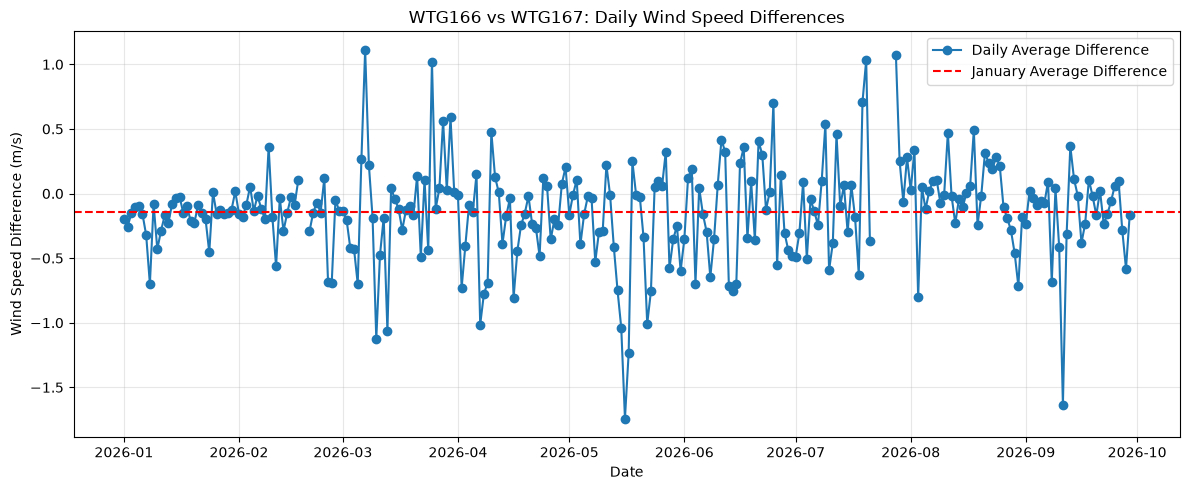

In [12]:
# Examine daily wind-speed differences for WTG166 and WTG167

difference = wind["wtg166"] - wind["wtg167"]

daily_difference = difference.resample("D").mean()

plt.figure(figsize=(12, 5))

plt.plot(daily_difference.index, daily_difference,
         marker="o", label="Daily Average Difference")

plt.axhline(
    difference.mean(),
    color="red",
    linestyle="--",
    label="January Average Difference"
)

plt.title("WTG166 vs WTG167: Daily Wind Speed Differences")
plt.xlabel("Date")
plt.ylabel("Wind Speed Difference (m/s)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [13]:
difference = (wind["wtg166"] - wind["wtg167"]).dropna()

daily_stats = difference.resample("D").agg(
    ["mean", "median", "std", "count"]
)

display(
    daily_stats.loc[
        ["2026-01-08", "2026-01-24"]
    ].round(3)
)

,mean,median,std,count
utc_time,,,,
2026-01-08,-0.700,-0.781,1.325,143
2026-01-24,-0.455,-0.265,1.432,144


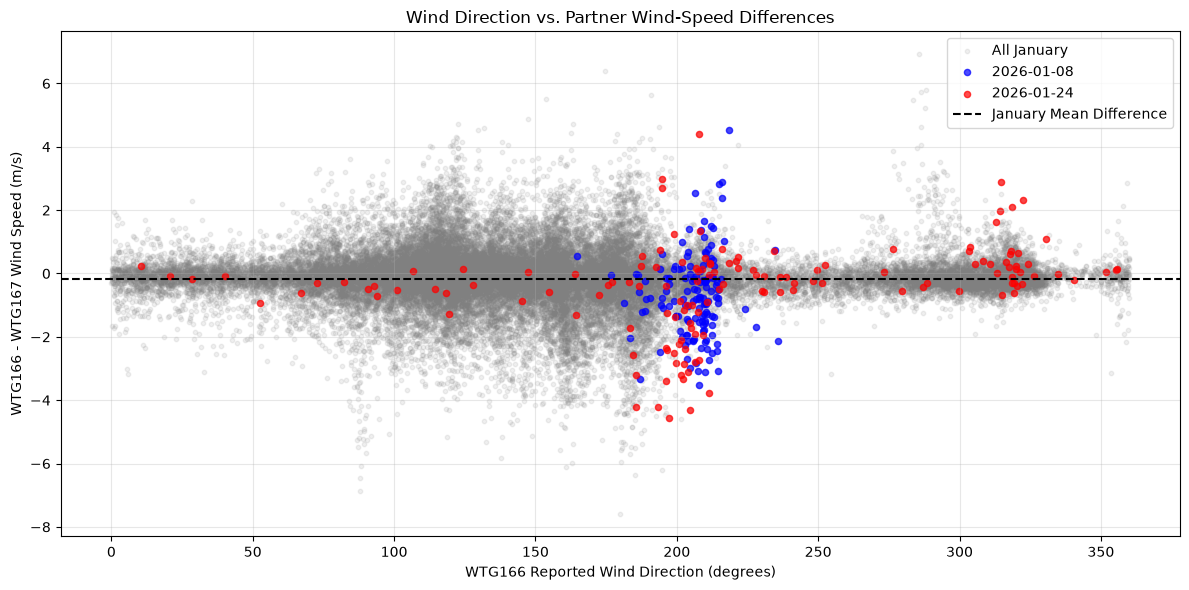

In [14]:
# Compare partner differences with wind direction
direction = turbines.xs(
    "wind_direction", axis=1, level="variable"
)["wtg166"]

check = pd.DataFrame({
    "difference": wind["wtg166"] - wind["wtg167"],
    "direction": direction
}).dropna()

check["direction"] = check["direction"] % 360

plt.figure(figsize=(12, 6))

# All January observations
plt.scatter(
    check["direction"],
    check["difference"],
    alpha=0.12,
    s=10,
    color="gray",
    label="All January"
)

# Highlight the two unusual days
for date, color in [
    ("2026-01-08", "blue"),
    ("2026-01-24", "red")
]:
    subset = check.loc[date]
    plt.scatter(
        subset["direction"],
        subset["difference"],
        s=20,
        alpha=0.7,
        color=color,
        label=date
    )

plt.axhline(
    -0.1797,
    color="black",
    linestyle="--",
    label="January Mean Difference"
)

plt.xlabel("WTG166 Reported Wind Direction (degrees)")
plt.ylabel("WTG166 - WTG167 Wind Speed (m/s)")
plt.title("Wind Direction vs. Partner Wind-Speed Differences")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [15]:
# Compare wind-speed differences across 20-degree wind sectors

check["sector"] = pd.cut(
    check["direction"],
    bins=np.arange(0, 361, 20),
    right=False
)

sector_stats = (
    check.groupby("sector", observed=True)["difference"]
    .agg(
        Observations="count",
        Mean="mean",
        Median="median",
        SD="std"
    )
    .round(3)
)

display(sector_stats)

,Observations,Mean,Median,SD
sector,,,,
"[0, 20)",841,-0.132,-0.109,0.502
"[20, 40)",983,-0.118,-0.076,0.510
"[40, 60)",925,-0.141,-0.105,0.496
"[60, 80)",1740,-0.054,-0.068,0.707
"[80, 100)",2944,-0.185,-0.120,0.976
"[100, 120)",5180,0.008,-0.009,0.980
"[120, 140)",4868,-0.053,-0.049,1.056
"[140, 160)",4501,-0.163,-0.115,1.089
"[160, 180)",4370,-0.295,-0.188,1.178


In [16]:
# Find the most consistent partners for WTG166
# when wind direction is between 200° and 220°

target = "wtg166"

sector_times = check.loc[
    (check["direction"] >= 200) &
    (check["direction"] < 220)
].index

results = []

for partner in wind.columns.drop(target):

    paired = wind.loc[
        sector_times, [target, partner]
    ].dropna()

    if len(paired) < 100:
        continue

    diff = paired[target] - paired[partner]

    results.append({
        "Partner": partner,
        "Correlation": paired[target].corr(paired[partner]),
        "Mean Difference": diff.mean(),
        "SD Difference": diff.std(),
        "Observations": len(paired)
    })

sector_partners = pd.DataFrame(results).sort_values(
    "SD Difference"
)

display(sector_partners.head(10).round(4))

print("\nWTG167 comparison:")
display(
    sector_partners[
        sector_partners["Partner"] == "wtg167"
    ].round(4)
)

,Partner,Correlation,Mean Difference,SD Difference,Observations
15,wtg167,0.9885,-0.2223,0.8461,1343
14,wtg165,0.9833,-0.0508,1.0459,1343
13,wtg164,0.9763,-0.0123,1.1931,1333
12,wtg163,0.9710,-0.2248,1.3151,1326
11,wtg162,0.9683,-0.2926,1.3758,1343
10,wtg161,0.9645,-0.5353,1.5100,1343
7,wtg157,0.9573,-1.1507,1.5743,1343
16,wtg168,0.9552,-0.2833,1.6683,1343
6,wtg156,0.9525,-0.2589,1.6687,1342
5,wtg155,0.9492,-0.8837,1.7132,1343



WTG167 comparison:


,Partner,Correlation,Mean Difference,SD Difference,Observations
15,wtg167,0.9885,-0.2223,0.8461,1343


In [17]:
# Compare WTG166–167 differences by wind speed and direction

direction_166 = turbines.xs(
    "wind_direction", axis=1, level="variable"
)["wtg166"]

comparison = pd.DataFrame({
    "wind166": wind["wtg166"],
    "wind167": wind["wtg167"],
    "direction": direction_166 % 360
}).dropna()

comparison["difference"] = (
    comparison["wind166"] - comparison["wind167"]
)

comparison["avg_speed"] = (
    comparison["wind166"] + comparison["wind167"]
) / 2

comparison["direction_group"] = np.where(
    comparison["direction"].between(200, 220, inclusive="left"),
    "200-220 degrees",
    "Other directions"
)

comparison["speed_bin"] = pd.cut(
    comparison["avg_speed"],
    bins=[0, 4, 6, 8, 10, 12, 15, 20, 40]
)

speed_stats = (
    comparison.groupby(
        ["speed_bin", "direction_group"],
        observed=True
    )["difference"]
    .agg(
        Observations="count",
        Mean="mean",
        SD="std"
    )
    .round(3)
)

display(speed_stats)

Observations   Mean     SD
speed_bin direction_group                             
(0, 4]    200-220 degrees            431 -0.228  0.417
          Other directions          9576 -0.133  0.360
(4, 6]    200-220 degrees            252 -0.135  0.573
          Other directions          5974 -0.095  0.576
(6, 8]    200-220 degrees            215 -0.142  0.836
          Other directions          5046 -0.071  0.795
(8, 10]   200-220 degrees            177 -0.300  0.961
          Other directions          3743 -0.090  0.974
(10, 12]  200-220 degrees             66  0.112  1.101
          Other directions          3382 -0.025  1.147
(12, 15]  200-220 degrees             59 -0.021  1.374
          Other directions          4017 -0.035  1.360
(15, 20]  200-220 degrees             69 -0.217  1.409
          Other directions          3042 -0.378  1.687
(20, 40]  200-220 degrees             74 -0.995  1.229
          Other directions          1089 -1.008  1.594

In [18]:
# Investigate unusually high wind speeds at 200–220 degrees

sector = comparison[
    comparison["direction_group"] == "200-220 degrees"
].copy()

print("Total sector observations:", len(sector))
print("Observations above 20 m/s:", (sector["avg_speed"] > 20).sum())
print("Observations above 25 m/s:", (sector["avg_speed"] > 25).sum())

print("\nHighest wind-speed observations:")

display(
    sector.nlargest(12, "avg_speed")[
        ["wind166", "wind167", "avg_speed",
         "direction", "difference"]
    ].round(3)
)

Total sector observations: 1343
Observations above 20 m/s: 74
Observations above 25 m/s: 12

Highest wind-speed observations:


,wind166,wind167,avg_speed,direction,difference
utc_time,,,,,
2026-01-08 20:30:00,25.770,28.854,27.312,214.550,-3.084
2026-01-08 20:20:00,25.732,28.120,26.926,210.566,-2.387
2026-01-08 22:50:00,25.759,27.687,26.723,212.566,-1.928
2026-01-08 23:00:00,25.815,27.427,26.621,212.286,-1.611
2026-01-08 20:40:00,26.203,26.965,26.584,209.258,-0.762
2026-01-08 00:50:00,26.658,26.262,26.460,211.303,0.396
2026-01-08 04:10:00,25.189,27.700,26.445,212.586,-2.510
2026-01-08 02:20:00,25.690,25.829,25.760,210.923,-0.140
2026-01-08 02:30:00,25.579,25.487,25.533,208.077,0.091


In [19]:
# Check whether January 8 high winds occurred across the farm

high_wind_times = sector.nlargest(12, "avg_speed").index

fleet = wind.loc[high_wind_times]

fleet_summary = pd.DataFrame({
    "WTG166": fleet["wtg166"],
    "WTG167": fleet["wtg167"],
    "Fleet Median Wind Speed": fleet.median(axis=1),
    "Turbines Above 20 m/s": (fleet > 20).sum(axis=1),
    "Turbines Above 25 m/s": (fleet > 25).sum(axis=1),
    "Valid Turbines": fleet.notna().sum(axis=1)
})

display(fleet_summary.sort_index().round(2))

,WTG166,WTG167,Fleet Median Wind Speed,Turbines Above 20 m/s,Turbines Above 25 m/s,Valid Turbines
utc_time,,,,,,
2026-01-08 00:50:00,26.66,26.26,16.00,20,13,45
2026-01-08 01:30:00,23.95,26.07,19.69,22,8,45
2026-01-08 02:20:00,25.69,25.83,23.12,38,17,45
2026-01-08 02:30:00,25.58,25.49,24.00,37,17,45
2026-01-08 02:40:00,24.62,26.24,23.34,36,11,45
2026-01-08 04:10:00,25.19,27.70,24.70,41,20,45
2026-01-08 04:20:00,24.59,25.96,24.55,41,17,45
2026-01-08 20:20:00,25.73,28.12,23.96,39,14,45
2026-01-08 20:30:00,25.77,28.85,23.39,43,16,45


In [20]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Use January SCADA wind-speed data
wind = wind.sort_index()

# Split chronologically: 70% training, 30% testing
split = int(len(wind) * 0.70)

train = wind.iloc[:split]
test = wind.iloc[split:]

results = []

for turbine in wind.columns:

    # Find best partner using TRAINING data only
    correlations = train.corr(min_periods=300)[turbine].drop(turbine).dropna()

    if correlations.empty:
        continue

    partner = correlations.idxmax()

    # Prepare training and testing observations
    train_pair = train[[turbine, partner]].dropna()
    test_pair = test[[turbine, partner]].dropna()

    if len(train_pair) < 300 or len(test_pair) < 100:
        continue

    # Train model
    model = LinearRegression()
    model.fit(train_pair[[partner]], train_pair[turbine])

    # Predict turbine wind speed from partner
    predicted = model.predict(test_pair[[partner]])
    actual = test_pair[turbine]

    results.append({
        "Turbine": turbine,
        "Partner": partner,
        "Training Correlation": correlations[partner],
        "Test RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "Test MAE": mean_absolute_error(actual, predicted),
        "Test R2": r2_score(actual, predicted),
        "Mean Error": (actual - predicted).mean()
    })

model_results = pd.DataFrame(results).sort_values("Test RMSE")

print("Number of turbines modeled:", len(model_results))
print("\nOverall prediction performance:")
print(model_results[["Test RMSE", "Test MAE", "Test R2"]].median().round(3))

print("\n10 best-predicted turbines:")
display(model_results.head(10).round(3))

print("\n10 worst-predicted turbines:")
display(model_results.tail(10).round(3))

Number of turbines modeled: 45

Overall prediction performance:
Test RMSE    1.098
Test MAE     0.786
Test R2      0.929
dtype: float64

10 best-predicted turbines:


,Turbine,Partner,Training Correlation,Test RMSE,Test MAE,Test R2,Mean Error
43,wtg196,wtg197,0.982,0.736,0.543,0.948,-0.075
44,wtg197,wtg196,0.982,0.763,0.550,0.947,0.075
23,wtg175,wtg176,0.979,0.782,0.548,0.948,0.169
4,wtg154,wtg153,0.991,0.808,0.623,0.970,0.175
5,wtg155,wtg154,0.987,0.811,0.618,0.965,-0.140
3,wtg153,wtg154,0.991,0.841,0.655,0.971,-0.175
24,wtg176,wtg175,0.979,0.844,0.599,0.948,-0.188
6,wtg156,wtg155,0.981,0.871,0.650,0.962,0.139
12,wtg163,wtg164,0.989,0.906,0.643,0.962,-0.215
41,wtg194,wtg195,0.978,0.929,0.673,0.920,-0.059



10 worst-predicted turbines:


,Turbine,Partner,Training Correlation,Test RMSE,Test MAE,Test R2,Mean Error
25,wtg177,wtg176,0.957,1.332,0.986,0.871,-0.132
7,wtg157,wtg158,0.975,1.337,1.009,0.909,0.538
37,wtg190,wtg189,0.979,1.338,0.814,0.873,-0.014
8,wtg158,wtg167,0.976,1.412,1.075,0.898,0.143
30,wtg182,wtg184,0.960,1.515,1.109,0.838,-0.183
20,wtg172,wtg174,0.961,1.594,1.146,0.834,0.393
19,wtg171,wtg172,0.924,1.685,1.303,0.771,0.454
26,wtg178,wtg179,0.975,1.773,1.174,0.871,0.418
21,wtg173,wtg170,0.920,1.875,1.368,0.667,-0.288
18,wtg170,wtg173,0.920,1.982,1.471,0.710,0.331


In [21]:
# Extract raw SCADA wind-speed measurements
wind = turbines.xs(
    "wind_speed_2",
    axis=1,
    level="variable"
).copy()

# Exclude turbines with documented generator failures
wind = wind.drop(
    columns=["wtg169", "wtg183"],
    errors="ignore"
)

# Ensure numeric measurements
wind = wind.apply(pd.to_numeric, errors="coerce")

# Check data availability and suspicious readings
print("Dataset shape:", wind.shape)
print("Start:", wind.index.min())
print("End:", wind.index.max())

print("\nMissing data percentage:")
print(round(wind.isna().mean().mean() * 100, 2), "%")

print("\nWind-speed readings above 40 m/s:")
print((wind > 40).sum().sum())

print("\nValid observations by month:")
print(wind.notna().resample("MS").sum().mean(axis=1).round(0))

Dataset shape: (39018, 45)
Start: 2026-01-01 08:00:00
End: 2026-09-29 06:50:00

Missing data percentage:
4.09 %

Wind-speed readings above 40 m/s:
70

Valid observations by month:
utc_time
2026-01-01    4409.0
2026-02-01    3568.0
2026-03-01    4445.0
2026-04-01    4314.0
2026-05-01    4410.0
2026-06-01    4306.0
2026-07-01    3491.0
2026-08-01    4437.0
2026-09-01    4042.0
Freq: MS, dtype: float64


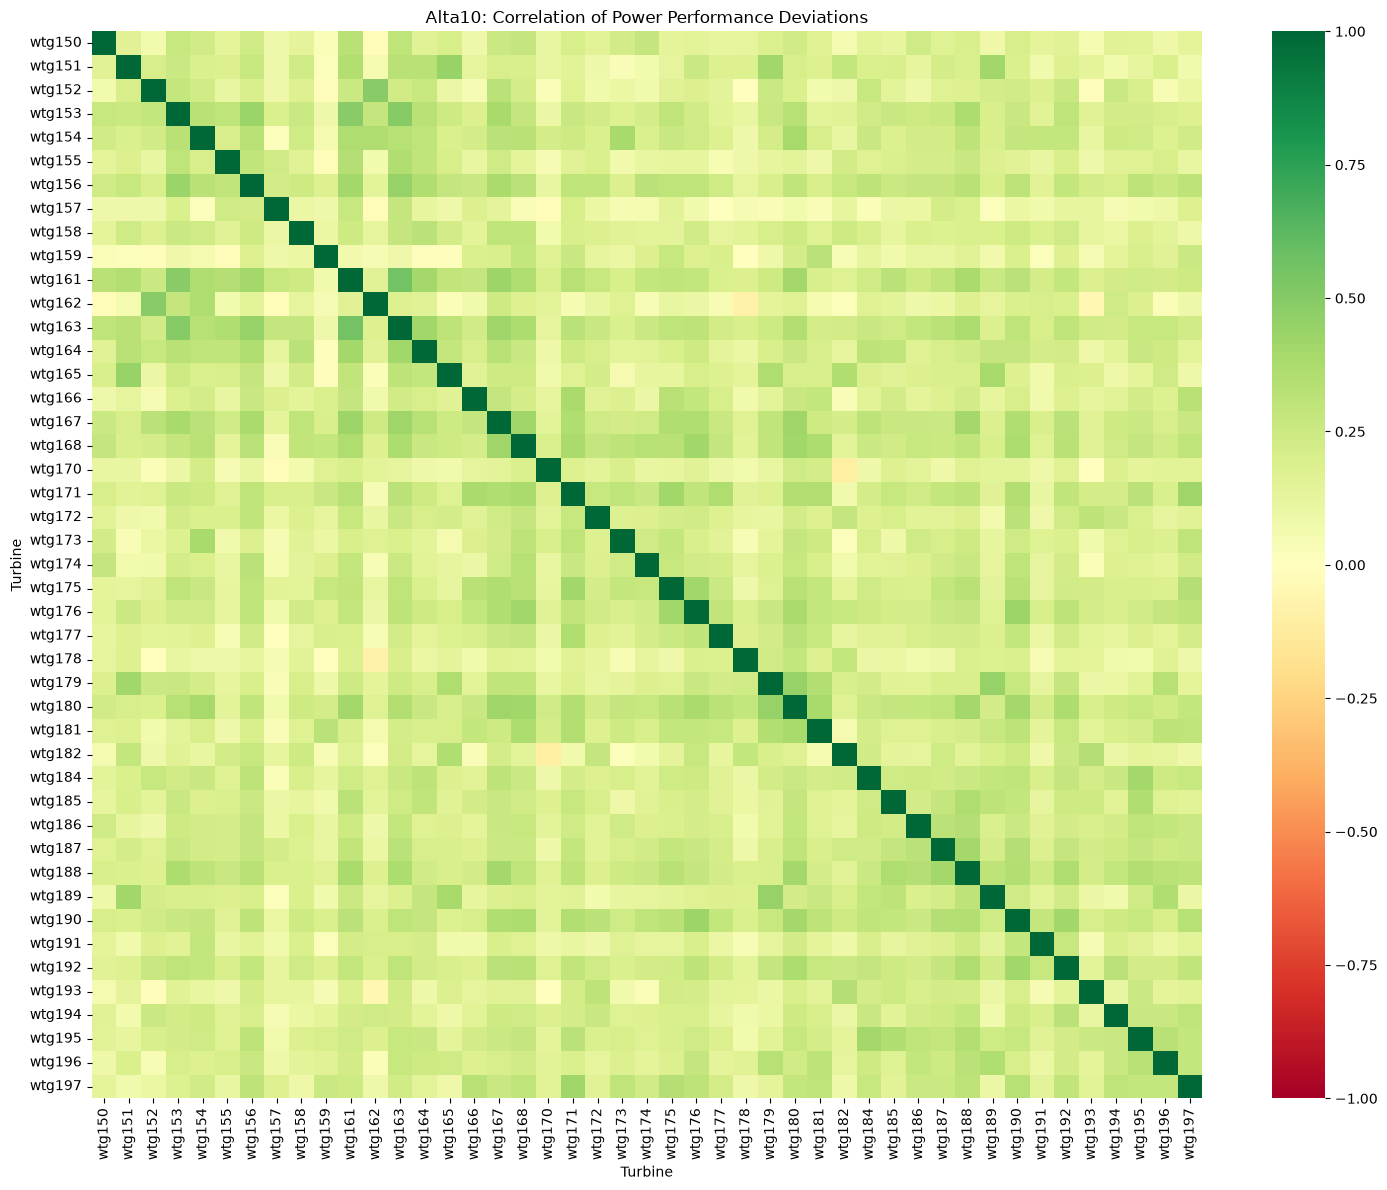

Top 10 correlated turbine pairs:


turbine  turbine
wtg161   wtg163     0.5606
wtg153   wtg163     0.4929
wtg152   wtg162     0.4862
wtg153   wtg161     0.4847
wtg179   wtg189     0.4525
wtg156   wtg163     0.4519
wtg179   wtg180     0.4472
wtg151   wtg165     0.4418
wtg153   wtg156     0.4370
wtg161   wtg167     0.4287
dtype: float64


Median pairwise correlation: 0.203


In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Extract actual and theoretical power
# real_power_a_c = KPI actual power in your formatted dataframe
actual = turbines.xs("real_power_a_c", axis=1, level="variable")
theoretical = turbines.xs("theoretical_power", axis=1, level="variable")

# Exclude turbines with known generator failures
exclude = ["wtg169", "wtg183"]
actual = actual.drop(columns=exclude, errors="ignore")
theoretical = theoretical.drop(columns=exclude, errors="ignore")

# Keep valid power measurements
# Avoid division by near-zero theoretical power
# Keep valid power measurements
valid = (
    theoretical.ge(300) &
    theoretical.le(3000) &
    actual.ge(0) &
    actual.le(3000)
)

# Calculate percentage deviation from theoretical power
power_deviation = (
    (actual - theoretical) / theoretical * 100
).where(valid)

# Correlate turbine deviations
power_corr = power_deviation.corr(min_periods=500)

# Display heatmap
plt.figure(figsize=(15, 12))

sns.heatmap(
    power_corr,
    cmap="RdYlGn",
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Alta10: Correlation of Power Performance Deviations")
plt.xlabel("Turbine")
plt.ylabel("Turbine")
plt.tight_layout()
plt.show()

# Identify strongest correlated pairs
mask = np.triu(np.ones(power_corr.shape, dtype=bool), k=1)
pairs = power_corr.where(mask).stack().sort_values(ascending=False)

print("Top 10 correlated turbine pairs:")
display(pairs.head(10).round(4))

print("\nMedian pairwise correlation:", round(pairs.median(), 4))


In [24]:
# Examine the distribution of power-performance deviations
deviations = power_deviation.stack().dropna()

print("Power deviation summary (%):")
print(
    deviations.describe(
        percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
    ).round(2)
)

print("\nPercentage of observations:")
print(f"Underperforming by >20%: {(deviations < -20).mean()*100:.2f}%")
print(f"Overperforming by >20%: {(deviations > 20).mean()*100:.2f}%")
print(f"Underperforming by >95%: {(deviations < -95).mean()*100:.2f}%")

Power deviation summary (%):
count    1023239.00
mean          -9.27
std           36.58
min         -100.00
1%          -100.00
5%          -100.00
25%           -8.36
50%            1.76
75%            5.68
95%           27.12
99%           58.59
max          832.98
dtype: float64

Percentage of observations:
Underperforming by >20%: 16.45%
Overperforming by >20%: 6.99%
Underperforming by >95%: 10.99%
